# 05 · Real-time data

Live data comes from the **stream service**, a background process that holds the websocket
connection to Massive. Massive allows **one connection per API key**, so notebooks never connect
themselves; they read what the service writes.

```
Massive websocket ──► stream service ──► live/<kind>/date=YYYY-MM-DD/part-*.parquet  (every 30 s)
  (one connection)     (launchd, always on)       merged into hour-*.parquet once the hour ends
                                                        │
                       notebooks / projects ◄── Store.live(), Store.follow(), bars(include_live=True)
```

Live data is **provisional**. The daily sync stores the official files the next morning, and
live days are pruned a week after the official data arrives.

| Channel | Stored as | Default subscription |
|---|---|---|
| `AM` minute bars | `bars_1m` | every ticker |
| `A` second bars | `bars_1s` | every ticker |
| `T` trades, `Q` quotes | `trades`, `quotes` | watchlist only (empty by default) |
| `LULD` limit up/down bands | `luld` | off |

This notebook works whether or not the market is open. Cells that need live data say so and
skip themselves when there is none.

In [1]:
from datetime import UTC, date, datetime, timedelta

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import clear_output, display
from massive_subspace_stream import Store
from subspace_probe import style

style()
pl.Config.set_tbl_rows(15)
pl.Config.set_tbl_width_chars(140)
store = Store()
NY = "America/New_York"

## 1 · Is the service running?

In [2]:
status = store.stream_status()
last = status.get("last_status", {})
print(f"running:       {status['running']}  (pid {status.get('pid', '-')})")
print(f"connected:     {last.get('connected')}  (connects since start: {last.get('connects')})")
print(f"subscriptions: {', '.join(last.get('subscriptions', [])) or '-'}")
print(f"started:       {last.get('started_at')}")
print(f"last message:  {last.get('last_message_at')}")
print(f"last flush:    {last.get('last_flush_at')}")
print(f"rows written:  {last.get('rows_written') or {}}")
print(f"last error:    {last.get('last_error')}")

running:       True  (pid 56538)
connected:     True  (connects since start: 1)
subscriptions: AM.*, A.*
started:       2026-10-31T20:57:38+00:00
last message:  2026-10-31T20:57:38+00:00
last flush:    2026-10-31T21:41:01+00:00
rows written:  {}
last error:    None


From a terminal: `uv run subspace stream status`, `uv run subspace service status`, and the
log at `~/market_data/massive/_logs/stream.launchd.log`. If the service is not running:
`uv run subspace service install --only stream`.

## 2 · Is the market open now?

Live bars arrive from 04:00 to 20:00 New York time on trading days (extended hours included).

In [3]:
now = datetime.now(UTC)
today = now.astimezone(__import__("zoneinfo").ZoneInfo(NY)).date()
trading_today = today in store.trading_days(today, today)
sess = store.sessions(today).row(0, named=True) if trading_today else None
if sess:
    ext_open = sess["market_open"] - timedelta(hours=5, minutes=30)   # 04:00 New York
    ext_close = sess["market_close"] + timedelta(hours=4)             # 20:00 New York (16:00 close)
    LIVE_NOW = ext_open <= now <= ext_close
else:
    LIVE_NOW = False
print(f"now: {now.astimezone(__import__('zoneinfo').ZoneInfo(NY)):%Y-%m-%d %H:%M} New York; "
      f"trading day: {trading_today}; live data flowing now: {LIVE_NOW}")

now: 2026-10-31 17:41 New York; trading day: False; live data flowing now: False


## 3 · What has been captured

`store.live(kind, tickers, start, end)` reads captured data like any other dataset. Each row
has `received_at`: the time the service wrote it.

In [4]:
recent = store.live("bars_1m", start=today - timedelta(days=10), end=today)
if recent.height == 0:
    print("No live data captured in the last 10 days yet. It appears once the service runs during market hours.")
    LIVE_DAY = None
else:
    LIVE_DAY = recent["date"].max()
    print(f"latest live day: {LIVE_DAY}")
    display(recent.group_by("date").agg(
        pl.len().alias("bars"), pl.col("ticker").n_unique().alias("tickers"),
        pl.col("timestamp").min().dt.convert_time_zone(NY).alias("first_bar"),
        pl.col("timestamp").max().dt.convert_time_zone(NY).alias("last_bar"),
        pl.col("received_at").max().alias("last_write"),
    ).sort("date"))

No live data captured in the last 10 days yet. It appears once the service runs during market hours.


In [5]:
if LIVE_DAY is not None:
    spy_live = store.live("bars_1m", "SPY", start=LIVE_DAY).sort("timestamp")
    display(spy_live.tail(5).select("ticker", pl.col("timestamp").dt.convert_time_zone(NY), "open", "high", "low", "close", "volume", "vwap", "day_volume", "received_at"))
else:
    print("skipped: no live data yet")

skipped: no live data yet


Live minute bars carry a few fields the official bars don't: `vwap` (the bar's volume-weighted
price), `day_open`, `day_volume` and `day_vwap` (running values for the day) and
`avg_trade_size`.

## 4 · One continuous series: official history + today's live bars

`bars(..., freq="1min", include_live=True)` appends live bars for days that don't have
official files yet, so a chart or signal can run right up to now:

shape: (3, 3)
┌────────────┬──────────┬──────┐
│ date       ┆ official ┆ bars │
│ ---        ┆ ---      ┆ ---  │
│ date       ┆ bool     ┆ u32  │
╞════════════╪══════════╪══════╡
│ 2026-10-28 ┆ true     ┆ 390  │
│ 2026-10-29 ┆ true     ┆ 390  │
│ 2026-10-30 ┆ true     ┆ 390  │
└────────────┴──────────┴──────┘


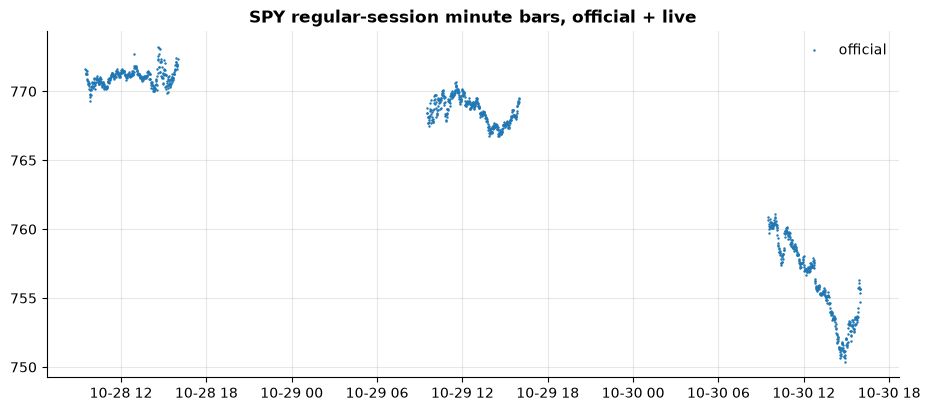

In [6]:
start = store.trading_days(today - timedelta(days=7), today)[-3]
series = store.bars("SPY", start=start, end=today, freq="1min", session="regular", include_live=True)
official_days = set(store.bars("SPY", start=start, end=today, freq="1min", session="regular")["date"].unique())
series = series.with_columns(pl.col("date").is_in(list(official_days)).alias("official"))
print(series.group_by("date", "official").agg(pl.len().alias("bars")).sort("date"))

fig, ax = plt.subplots()
for official, g in series.group_by("official"):
    ax.plot(g["timestamp"].dt.convert_time_zone(NY).to_list(), g["close"].to_list(), ".", ms=1.5,
            label="official" if official[0] else "live (provisional)")
ax.set_title("SPY regular-session minute bars, official + live")
ax.legend();

## 5 · Following new data as it arrives

`store.follow(kind, tickers, poll_seconds, timeout)` is a generator that yields a DataFrame of
new rows each time the service writes some. It only returns rows received after it started
(pass `since=` to start earlier). New data appears once per flush, every 30 seconds by default.

The function below redraws a chart of the latest prices for a few tickers as minute bars
arrive. It runs only while the market is open; set `MINUTES` to watch longer.

In [7]:
def watch(tickers: list[str], minutes: float = 2, kind: str = "bars_1m") -> pl.DataFrame:
    """Live chart: today's bars so far, then extend it with each new batch."""
    history = store.live(kind, tickers, start=today)
    if history.height:
        history = history.select("ticker", "timestamp", "close", "received_at")
    for batch in store.follow(kind, tickers, poll_seconds=5, timeout=minutes * 60):
        new = batch.select("ticker", "timestamp", "close", "received_at")
        history = new if history.height == 0 else pl.concat([history, new]).unique(["ticker", "timestamp"], keep="last")
        clear_output(wait=True)
        fig, ax = plt.subplots()
        for (t,), g in history.sort("timestamp").group_by("ticker", maintain_order=True):
            base = g["close"][0]
            ax.plot(g["timestamp"].dt.convert_time_zone(NY).to_list(), ((g["close"] / base - 1) * 100).to_list(), label=t)
        ax.set_title(f"Live: % change since first bar today (updated {datetime.now():%H:%M:%S}, {len(new)} new rows)")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=__import__("zoneinfo").ZoneInfo(NY)))
        ax.legend()
        plt.show()
    return history


MINUTES = 2
if LIVE_NOW and status["running"]:
    watched = watch(["SPY", "QQQ", "IWM"], minutes=MINUTES)
else:
    print("skipped: the market is closed or the stream service is not running. "
          "Run this cell during market hours (04:00-20:00 New York on trading days).")

skipped: the market is closed or the stream service is not running. Run this cell during market hours (04:00-20:00 New York on trading days).


The same pattern works for any live kind. For example, second bars (`bars_1s`) for a few names:

```python
for batch in store.follow("bars_1s", ["NVDA", "TSLA"], timeout=120):
    print(batch.group_by("ticker").agg(pl.col("close").last(), pl.col("volume").sum()))
```

`follow` is built for research and monitoring: data shows up after each 30-second flush. A
trading process that needs every tick within milliseconds should get its own stream feed
(a future core package), not poll files.

## 6 · Live vs official: how close is provisional data?

Once the official minute bars for a captured day arrive (the next morning), compare them with
what the stream recorded. Differences come from late trade reports and corrections that the
official files include.

In [8]:
def reconcile(day: date, tickers: list[str]) -> pl.DataFrame:
    live = store.live("bars_1m", tickers, start=day).select("ticker", "timestamp", pl.col("close").alias("live_close"), pl.col("volume").alias("live_volume"))
    official = store.bars(tickers, start=day, end=day, freq="1min").select("ticker", "timestamp", pl.col("close").alias("official_close"), pl.col("volume").alias("official_volume"))
    both = official.join(live, on=["ticker", "timestamp"], how="full", coalesce=True)
    return both.group_by("ticker").agg(
        pl.col("official_close").is_not_null().sum().alias("official_bars"),
        pl.col("live_close").is_not_null().sum().alias("live_bars"),
        ((pl.col("live_close") - pl.col("official_close")).abs() < 0.005).mean().mul(100).round(1).alias("close_match_pct"),
        (pl.col("live_volume").sum() / pl.col("official_volume").sum() * 100).round(1).alias("live_volume_pct_of_official"),
    ).sort("ticker")


official_last = store.coverage().filter(pl.col("dataset") == "bars_minute")["last"].item()
overlap = [] if recent.height == 0 else sorted(d for d in recent["date"].unique() if d.isoformat() <= official_last)
if overlap:
    print(f"comparing live vs official for {overlap[-1]}")
    display(reconcile(overlap[-1], ["SPY", "AAPL", "NVDA"]))
else:
    print("skipped: no day has both live and official data yet (needs one captured trading day plus the next morning's sync).")

skipped: no day has both live and official data yet (needs one captured trading day plus the next morning's sync).


## 7 · Adding trades and quotes for a watchlist

By default the service subscribes to minute and second bars for every ticker. Trades and
quotes for all tickers would be far too much, so they are streamed for a **watchlist**. Put the
settings in `~/.config/collective-alpha/collective.toml` (found from any directory, including
by the background service):

```toml
[massive_subspace_stream]
stream_watchlist = ["SPY", "QQQ", "AAPL", "NVDA"]
stream_watchlist_channels = ["T", "Q"]     # trades and quotes
# stream_channels = ["AM", "A"]            # what everyone gets (default)
# stream_flush_seconds = 30                # how often live files are written
```

Then restart the service so it picks up the change:

```bash
uv run subspace service install --only stream
uv run subspace stream status
```

Watchlist trades and quotes are then available with `store.live("trades", "AAPL", start=today)`
and `store.follow("quotes", ["SPY"])`.

## Takeaways
- The stream service owns the single websocket; check it with `store.stream_status()`.
- `store.live()` for captured data, `store.follow()` for new rows as they land,
  `bars(include_live=True)` for history that runs up to now.
- Live data is provisional and replaced by official files the next day.